# START ANALYSIS

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv('dirty_cafe_sales.csv')

df.columns

Index(['Transaction ID', 'Item', 'Quantity', 'Price Per Unit', 'Total Spent',
       'Payment Method', 'Location', 'Transaction Date'],
      dtype='str')

# DATA CLEANING PROCESS

In [3]:
# Duplicate/Backup DataFrame
df_clean = df.copy()

In [4]:
# Check Exact Duplicate
print(df_clean.duplicated().sum())

0


## 1. Transaction ID

In [5]:
# Check Duplicate Transaction ID
print(df_clean['Transaction ID'].duplicated().sum())

# Check Missing Value Transaction ID
print(df_clean['Transaction ID'].isna().sum())

# Check Data Type Transaction ID
print(df_clean['Transaction ID'].dtype)

# Check Values Transaction ID
print(df_clean['Transaction ID'].head(25))

0
0
str
0     TXN_1961373
1     TXN_4977031
2     TXN_4271903
3     TXN_7034554
4     TXN_3160411
5     TXN_2602893
6     TXN_4433211
7     TXN_6699534
8     TXN_4717867
9     TXN_2064365
10    TXN_2548360
11    TXN_3051279
12    TXN_7619095
13    TXN_9437049
14    TXN_8915701
15    TXN_2847255
16    TXN_3765707
17    TXN_6769710
18    TXN_8876618
19    TXN_3709394
20    TXN_3522028
21    TXN_3567645
22    TXN_5132361
23    TXN_2616390
24    TXN_9400181
Name: Transaction ID, dtype: str


In [6]:
# Check Advance Missing Value
print(df_clean['Transaction ID'].astype(dtype='str').str.strip().str.lower().isin(['', 'nan', 'n/a', 'null', 'none', '?']).sum())

# Check White space
whitespace_txid = (
    df_clean['Transaction ID'].astype('str') != df_clean['Transaction ID'].astype('str').str.strip().sum()
)

print(f"entries with whitespace: {whitespace_txid}")
print(whitespace_txid.value_counts().sum())

0
entries with whitespace: 0       True
1       True
2       True
3       True
4       True
        ... 
9995    True
9996    True
9997    True
9998    True
9999    True
Name: Transaction ID, Length: 10000, dtype: bool
10000


In [7]:
print(df_clean['Transaction ID'].astype('str'))

0       TXN_1961373
1       TXN_4977031
2       TXN_4271903
3       TXN_7034554
4       TXN_3160411
           ...     
9995    TXN_7672686
9996    TXN_9659401
9997    TXN_5255387
9998    TXN_7695629
9999    TXN_6170729
Name: Transaction ID, Length: 10000, dtype: str


In [8]:
print(df_clean['Transaction ID'].astype('str').str.strip())

0       TXN_1961373
1       TXN_4977031
2       TXN_4271903
3       TXN_7034554
4       TXN_3160411
           ...     
9995    TXN_7672686
9996    TXN_9659401
9997    TXN_5255387
9998    TXN_7695629
9999    TXN_6170729
Name: Transaction ID, Length: 10000, dtype: str


## 1. Mapping and Fill ERROR/NaN To Unknown Value In Item

In [9]:
# Check typo/inconsistent/missing Column Item
print(df_clean['Item'].value_counts(dropna=False))

Item
Juice       1171
Coffee      1165
Salad       1148
Cake        1139
Sandwich    1131
Smoothie    1096
Cookie      1092
Tea         1089
UNKNOWN      344
NaN          333
ERROR        292
Name: count, dtype: int64


In [10]:
print(df_clean['Item'].dtypes)

str


In [11]:
# Mapping UNKNOWN, NaN, ERROR to Missing Value (NULL)
invalid_item = [
    'UNKNOWN',
    'NaN',
    'ERROR'
]

# We using np.nan because dtypes is str
df_clean['Item'] = df_clean['Item'].replace(invalid_item, np.nan)

In [12]:
print(df_clean['Item'].value_counts(dropna=False))

Item
Juice       1171
Coffee      1165
Salad       1148
Cake        1139
Sandwich    1131
Smoothie    1096
Cookie      1092
Tea         1089
NaN          969
Name: count, dtype: int64


In [13]:
df_clean['Item'] = df_clean['Item'].fillna('Unknown')

In [14]:
print(df_clean['Item'].isna().sum())
print(df_clean['Item'].value_counts(dropna=False).sort_index(ascending=False))
print(df_clean['Item'].dtypes)

0
Item
Unknown      969
Tea         1089
Smoothie    1096
Sandwich    1131
Salad       1148
Juice       1171
Cookie      1092
Coffee      1165
Cake        1139
Name: count, dtype: int64
str


## 2. Mapping and Fill ERROR/UNKNOWN/NULL Value To 0 In Quantity

In [15]:
# Check typo/inconsistent/null Quantity
print(df_clean['Quantity'].isna().sum())
print(df_clean['Quantity'].value_counts(dropna=False))
print(df_clean['Quantity'].dtypes)

138
Quantity
5          2013
2          1974
4          1863
3          1849
1          1822
UNKNOWN     171
ERROR       170
NaN         138
Name: count, dtype: int64
str


In [16]:
# Mapping UNKNOWN/ERROR to Missing Value(NULL)
invalid_quantity = [
    'UNKNOWN',
    'ERROR'
]

df_clean['Quantity'] = df_clean['Quantity'].replace(invalid_quantity, np.nan)
print(df_clean['Quantity'].value_counts(dropna=False))

Quantity
5      2013
2      1974
4      1863
3      1849
1      1822
NaN     479
Name: count, dtype: int64


In [17]:
# Change Missing Value (NULL) to 0 
# Change dtype str -> int
df_clean['Quantity'] = df_clean['Quantity'].fillna(0).astype(dtype='int')

In [18]:
# Validation
print(df_clean['Quantity'].dtypes)
print(df_clean['Quantity'].value_counts(dropna=False))

int64
Quantity
5    2013
2    1974
4    1863
3    1849
1    1822
0     479
Name: count, dtype: int64


## 3. Mapping ERROR/UNKNOWN/NULL Value To 0 and Change Data Type To Float In Price Per Unit

In [19]:
print(df_clean['Price Per Unit'].isna().sum())
print(df_clean['Price Per Unit'].value_counts(dropna=False).sort_index(ascending=False))
print(df_clean['Price Per Unit'].dtypes)

179
Price Per Unit
UNKNOWN     164
ERROR       190
5.0        1204
4.0        2331
3.0        2429
2.0        1227
1.5        1133
1.0        1143
NaN         179
Name: count, dtype: int64
str


In [20]:
# MAPPING ERROR/UNKNOWN TO NaN Value
invalid_priceperunit = [
    'ERROR',
    'UNKNOWN',
    'NaN'
]
df_clean['Price Per Unit'] = df_clean['Price Per Unit'].replace(invalid_priceperunit, np.nan)

In [21]:
df_clean['Price Per Unit'] = pd.to_numeric(df_clean['Price Per Unit'])
print(df_clean['Price Per Unit'].dtypes)

float64


In [22]:
# FILL NaN value to 0
# CHANGING DATA TYPE TO INT
df_clean['Price Per Unit'] = df_clean['Price Per Unit'].fillna(0).astype('int')

In [23]:
# VALIDATION Price Per Unit
print(df_clean['Price Per Unit'].isna().sum())
print(df_clean['Price Per Unit'].value_counts(dropna=False))

0
Price Per Unit
3    2429
4    2331
1    2276
2    1227
5    1204
0     533
Name: count, dtype: int64


## 4. Mapping ERROR/UNKNOWN Value to Null and Convert Data Type Transaction Date To DateTime

In [24]:
# Checking missing value
print(df_clean['Transaction Date'].isna().sum())

159


In [25]:
print(df_clean['Transaction Date'].value_counts())

Transaction Date
UNKNOWN       159
ERROR         142
2023-02-06     40
2023-06-16     40
2023-03-13     39
             ... 
2023-09-24     15
2023-07-30     15
2023-03-11     14
2023-07-22     14
2023-02-17     14
Name: count, Length: 367, dtype: int64


In [26]:
# Mapping ERROR/UNKNOWN to NULL
dates_mapping = [
    'ERROR',
    'UNKNOWN'
]

df_clean['Transaction Date'] = df_clean['Transaction Date'].replace(dates_mapping, np.nan)
print(df_clean['Transaction Date'].value_counts(dropna=False))
print(df_clean['Transaction Date'].dtypes)

Transaction Date
NaN           460
2023-02-06     40
2023-06-16     40
2023-03-13     39
2023-07-21     39
             ... 
2023-09-24     15
2023-07-30     15
2023-03-11     14
2023-07-22     14
2023-02-17     14
Name: count, Length: 366, dtype: int64
str


In [27]:
# Convert format transaction date to datetime
converted_dates = pd.to_datetime(df_clean['Transaction Date'], errors='coerce')
df_clean['Transaction Date'] = converted_dates


print(df_clean['Transaction Date'].value_counts(dropna=False))
print(df_clean['Transaction Date'].dtypes)

Transaction Date
NaT           460
2023-02-06     40
2023-06-16     40
2023-03-13     39
2023-07-21     39
             ... 
2023-09-24     15
2023-07-30     15
2023-03-11     14
2023-07-22     14
2023-02-17     14
Name: count, Length: 366, dtype: int64
datetime64[us]


In [28]:
# Validation Transaction Date
print(df_clean['Transaction Date'].isna().sum())
print(df_clean['Transaction Date'].value_counts(dropna=False))
print(df_clean['Transaction Date'].dtypes)

460
Transaction Date
NaT           460
2023-02-06     40
2023-06-16     40
2023-03-13     39
2023-07-21     39
             ... 
2023-09-24     15
2023-07-30     15
2023-03-11     14
2023-07-22     14
2023-02-17     14
Name: count, Length: 366, dtype: int64
datetime64[us]


## 5. Mapping and Fill UNKNOWN/ERROR/NaN to 0 In Total Spent

In [29]:
print(df_clean['Total Spent'].isna().sum())
print(df_clean['Total Spent'].value_counts(dropna=False).sort_index(ascending=False))
print(df_clean['Total Spent'].dtypes)

173
Total Spent
UNKNOWN    165
ERROR      164
9.0        479
8.0        677
7.5        237
6.0        979
5.0        468
4.5        225
4.0        923
3.0        930
25.0       259
20.0       746
2.0        497
16.0       444
15.0       734
12.0       939
10.0       524
1.5        205
1.0        232
NaN        173
Name: count, dtype: int64
str


In [30]:
# Mapping Unknown/Erorr value to Missing Value (Null)
invalid_spent = [
    'UNKNOWN',
    'ERROR'
]

df_clean['Total Spent'] = df['Total Spent'].replace(invalid_spent, np.nan)
print(df_clean['Total Spent'].value_counts(dropna=False))

Total Spent
6.0     979
12.0    939
3.0     930
4.0     923
20.0    746
15.0    734
8.0     677
10.0    524
NaN     502
2.0     497
9.0     479
5.0     468
16.0    444
25.0    259
7.5     237
1.0     232
4.5     225
1.5     205
Name: count, dtype: int64


In [31]:
# Fill NaN to 0
# Change dtypes str to int
df_clean['Total Spent'] = (
    pd.to_numeric(
        df_clean['Total Spent']
    ).fillna(0).astype('int')
)
print(df_clean['Total Spent'].dtypes)

int64


In [32]:
# VALIDATION
print(df_clean['Total Spent'].isna().sum())
print(df_clean['Total Spent'].value_counts(dropna=False).sort_index(ascending=False))
print(df_clean['Total Spent'].dtypes)

0
Total Spent
25     259
20     746
16     444
15     734
12     939
10     524
9      479
8      677
7      237
6      979
5      468
4     1148
3      930
2      497
1      437
0      502
Name: count, dtype: int64
int64


In [33]:
# # 1. Remove the thousands separator (.)
# df_clean["Total Spent"] = df_clean["Total Spent"].astype(str).str.replace(".", "", regex=False)

# # 2. Swap the decimal comma (,) to a standard Python decimal point (.)
# df_clean["Total Spent"] = df_clean["Total Spent"].str.replace(",", ".", regex=False)

# # 3. Strip any leftover currency signs or spaces
# df_clean["Total Spent"] = df_clean["Total Spent"].str.replace(r"[^\d.-]", "", regex=True)

# # 4. Convert cleanly to Float
# df_clean["Total Spent"] = pd.to_numeric(df_clean["Total Spent"], errors="coerce")

## 6. Mapping and Fill ERROR/NaN value to Unknown In Paymemt Method

In [34]:
print(df_clean['Payment Method'].isna().sum())
print(df_clean['Payment Method'].value_counts(dropna=False).sort_index(ascending=False))
print(df_clean['Payment Method'].dtypes)

2579
Payment Method
UNKNOWN            293
ERROR              306
Digital Wallet    2291
Credit Card       2273
Cash              2258
NaN               2579
Name: count, dtype: int64
str


In [35]:
# Mapping Error to Unknown Value
invalid_payment = [
    'NaN',
    'ERROR',
    'UNKNOWN'
]
df_clean['Payment Method'] = df_clean['Payment Method'].replace(invalid_payment, 'Unknown')

# Fill NaN to Unknown Value
df_clean['Payment Method'] = df_clean['Payment Method'].fillna('Unknown')

In [36]:
df_clean['Payment Method'].value_counts(dropna=False).sort_index(ascending=False)

Payment Method
Unknown           3178
Digital Wallet    2291
Credit Card       2273
Cash              2258
Name: count, dtype: int64

## 7. Mapping and Fill ERROR/NaN To Unknown Value

In [37]:
print(df_clean['Location'].isna().sum())
print(df_clean['Location'].value_counts(dropna=False).sort_index(ascending=False))
print(df_clean['Location'].dtypes)

3265
Location
UNKNOWN      338
Takeaway    3022
In-store    3017
ERROR        358
NaN         3265
Name: count, dtype: int64
str


In [38]:
# Fill NaN Value To ERROR
df_clean['Location'] = df_clean['Location'].fillna('ERROR')
print(df_clean['Location'].value_counts(dropna=False).sort_index(ascending=False))

Location
UNKNOWN      338
Takeaway    3022
In-store    3017
ERROR       3623
Name: count, dtype: int64


In [39]:
# Mapping ERROR Value to Unknown
invalid_location = [
    'UNKNOWN',
    'ERROR'
]
df_clean['Location'] = df_clean['Location'].replace(invalid_location, 'Unknown')
print(df_clean['Location'].value_counts(dropna=False).sort_index(ascending=False))

Location
Unknown     3961
Takeaway    3022
In-store    3017
Name: count, dtype: int64


In [40]:
# Validation
print(df_clean['Location'].isna().sum())
print(df_clean['Location'].value_counts(dropna=False).sort_index(ascending=False))
print(df_clean['Location'].dtypes)

0
Location
Unknown     3961
Takeaway    3022
In-store    3017
Name: count, dtype: int64
str


# SECOND PHASE CLEANNING PROCESS

## Cross-Imputation For Column Quantity, Price Per Unit, Total Spent

In [41]:
cols_to_check = ['Quantity', 'Price Per Unit', 'Total Spent']
print('missing value before cross-imputation:')
print(df_clean[cols_to_check].isna().sum())

missing value before cross-imputation:
Quantity          0
Price Per Unit    0
Total Spent       0
dtype: int64


In [42]:
# Terapkan aturan khusus: Jika Item adalah 'Tea', set Price Per Unit menjadi 1.0
df_clean.loc[df_clean['Item'] == 'Tea', 'Price Per Unit'] = 1.0

In [43]:
for col in cols_to_check:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(
            df_clean[col].astype(str)
            .str.lower()
            .replace(['unknown', 'error', '0', 'nan', 'none'], np.nan)
        )

mask_ts = df_clean['Total Spent'].isna() & df_clean['Quantity'].notnull() & df_clean['Price Per Unit'].notnull()
df_clean.loc[mask_ts, 'Total Spent'] = df_clean['Quantity'] * df_clean['Price Per Unit']

mask_qty = df_clean['Quantity'].isna() & df_clean['Quantity'].notnull() & df_clean['Price Per Unit'].notnull() & (df_clean['Price Per Unit'] != 0)
df_clean.loc[mask_qty, 'Quantity'] = df_clean['Total Spent'] / df_clean['Price Per Unit']

mask_ppu = df_clean['Price Per Unit'].isna() & df_clean['Quantity'].notnull() & df_clean['Total Spent'].notnull() & (df_clean['Quantity'] != 0)
df_clean.loc[mask_ppu, 'Price Per Unit'] = df_clean['Total Spent'] / df_clean['Quantity']

print('left over missing value after cross-imputation:')
print(df_clean[cols_to_check].isna().sum())

left over missing value after cross-imputation:
Quantity          479
Price Per Unit     31
Total Spent        37
dtype: int64


In [44]:
# 1. Pastikan kolom 'Item' bertipe string dan bersih dari spasi/huruf kapital aneh
df_clean['Item'] = df_clean['Item'].astype(str).str.strip().str.title()

# 2. Untuk item lainnya (Juice, Coffee, dll.), isi nilai NaN menggunakan median harga dari item yang sama
item_median_prices = df_clean.groupby('Item')['Price Per Unit'].transform('median')
df_clean['Price Per Unit'] = df_clean['Price Per Unit'].fillna(item_median_prices)


In [45]:
mask_qty_missing = df_clean['Quantity'].isna()
mask_tp = df_clean['Total Spent'].isna()

df_clean.loc[mask_qty_missing, 'Quantity'] = (
    df_clean.loc[mask_qty_missing, 'Total Spent'] / df_clean.loc[mask_qty_missing, 'Price Per Unit']
)

df_clean.loc[mask_tp, 'Total Spent'] = (
    df_clean.loc[mask_tp, 'Quantity'] * df_clean.loc[mask_tp, 'Price Per Unit']
)

In [46]:
df_clean = df_clean.dropna(subset='Quantity')

## Reverse Lookup for Column Item Reference From Column Price Per Unit

In [47]:
unkn_mask = (
    (df_clean['Transaction ID'] == 'Unknown') |
    (df_clean['Payment Method'] == 'Unknown') |
    (df_clean['Item'] == 'Unknown')
)

display(df_clean[unkn_mask])

print("Total rows with value 'Unknown':", unkn_mask.sum())

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
3,TXN_7034554,Salad,2.0,5.0,10.0,Unknown,Unknown,2023-04-27
6,TXN_4433211,Unknown,3.0,3.0,9.0,Unknown,Takeaway,2023-10-06
8,TXN_4717867,Unknown,5.0,3.0,15.0,Unknown,Takeaway,2023-07-28
9,TXN_2064365,Sandwich,5.0,4.0,20.0,Unknown,In-store,2023-12-31
13,TXN_9437049,Cookie,5.0,1.0,5.0,Unknown,Takeaway,2023-06-01
...,...,...,...,...,...,...,...,...
9988,TXN_9594133,Cake,5.0,3.0,15.0,Unknown,Unknown,NaT
9992,TXN_2739140,Smoothie,4.0,4.0,16.0,Unknown,In-store,2023-07-05
9994,TXN_7851634,Unknown,4.0,4.0,16.0,Unknown,Unknown,2023-01-08
9995,TXN_7672686,Coffee,2.0,2.0,4.0,Unknown,Unknown,2023-08-30


Total rows with value 'Unknown': 3839


In [48]:
price_reference = df_clean[
    ~df_clean['Item'].isin(['Unknown'])
].groupby('Item')['Price Per Unit'].agg(['min', 'max', 'mean', 'count'])

display(price_reference)

,min,max,mean,count
Item,,,,
Cake,3.0,3.0,3.0,1138
Coffee,2.0,2.0,2.0,1160
Cookie,1.0,1.0,1.0,1090
Juice,3.0,3.0,3.0,1168
Salad,5.0,5.0,5.0,1146
Sandwich,4.0,4.0,4.0,1127
Smoothie,4.0,4.0,4.0,1094
Tea,1.0,1.0,1.0,1088


In [49]:
# 1. Define a dictionary mapping for unique prices or top-priority items
# Note: For prices 1, 3, and 4, which have duplicates, we can either select one of them or skip them for now
price_to_item_unique = {
    2.0: 'Coffee',
    5.0: 'Salad'
    # 1.0, 3.0, and 4.0 contain more than 1 item (overlap)
}

# 2. Function to fill in 'Unknown' or empty items based on unique prices
def impute_unique_items(row):
    item_val = str(row['Item']).strip().lower()
    if item_val in ['unknown', 'nan', '']:
        price = row['Price Per Unit']
        # Retrieve from unique mapping
        return price_to_item_unique.get(price, row['Item'])
    return row['Item']

# 3. Apply to the DataFrame
df_clean['Item'] = df_clean.apply(impute_unique_items, axis=1)

In [50]:
# 1. Convert the 'unknown' text variations to NaN for consistency, then remove the rows where the Item is NaN.
df_clean['Item'] = df_clean['Item'].replace(['unknown', 'Unknown', 'UNKNOWN', ''], np.nan)

# 2. Drop rows where the 'Item' column has a NaN value
df_clean = df_clean.dropna(subset=['Item'])

# Double-check the number of rows or ensure that no 'Unknown' values ​​remain
print("Remain rows after droping :", len(df_clean))

Remain rows after droping : 9261


## Drop unknown values for column Payment Method & Location

In [51]:
df_clean['Payment Method'] = df_clean['Payment Method'].replace(['unknown', 'Unknown', 'UNKNOWN', ''], np.nan)
df_clean = df_clean.dropna(subset=['Payment Method'])

print("Remain rows after droping:", len(df_clean))

Remain rows after droping: 6318


In [52]:
df_clean['Location'] = df_clean['Location'].replace(['unknown', 'Unknown', 'UNKNOWN', ''], np.nan)
df_clean = df_clean.dropna(subset=['Location'])

print("Remain rows after droping:", len(df_clean))

Remain rows after droping: 3846


# VISUALIZATION

findfont: Failed to find font weight semibold, now using 700.


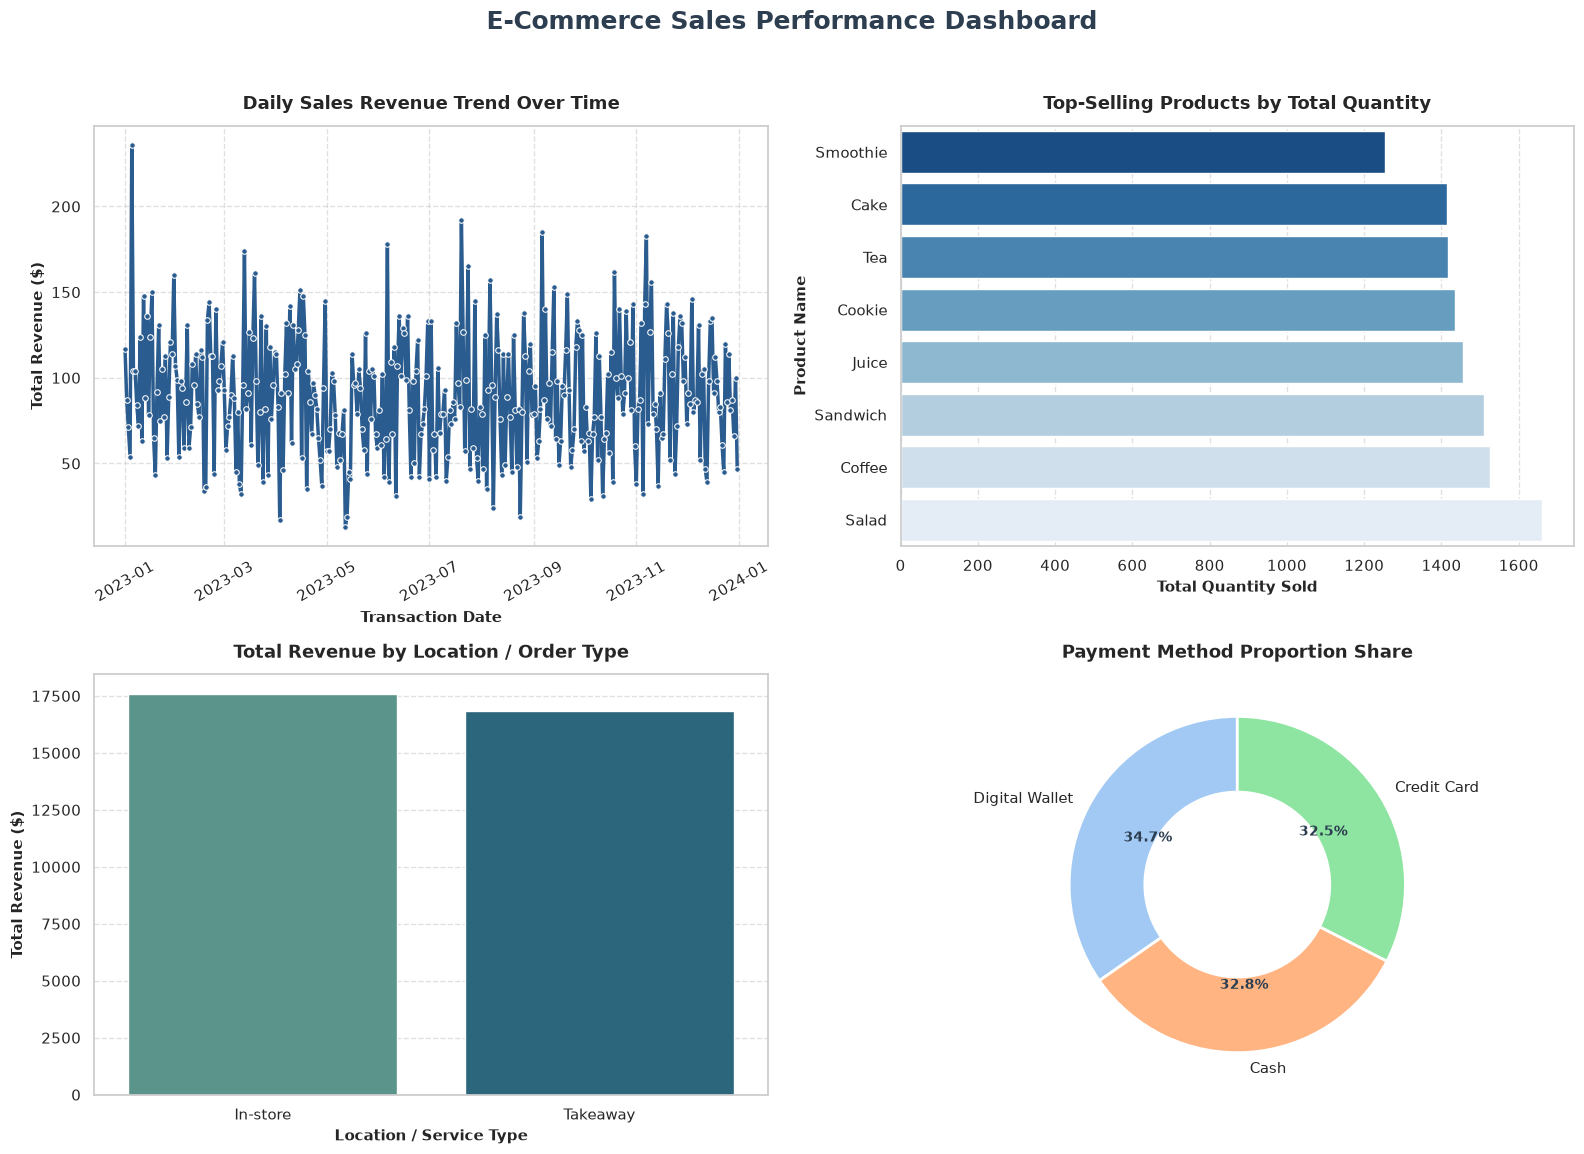

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Mengatur tema visualisasi secara profesional
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']

# Membuat kanvas grid 2x2 dengan ukuran yang proporsional
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('E-Commerce Sales Performance Dashboard', fontsize=18, fontweight='bold', y=0.96, color='#2c3e50')

# Warna palet utama yang selaras
primary_color = '#2b5c8f'
palette_blues = sns.color_palette("Blues_r", 8)
palette_warm = sns.color_palette("YlOrBr_r", 5)

# --- 1. TOP LEFT: Daily Sales Trend (Line Chart) ---
daily_sales = df_clean.groupby('Transaction Date')['Total Spent'].sum().reset_index()

sns.lineplot(
    ax=axes[0, 0], data=daily_sales, x='Transaction Date', y='Total Spent', 
    color=primary_color, linewidth=2.5, marker='o', markersize=4
)
axes[0, 0].set_title('Daily Sales Revenue Trend Over Time', fontsize=13, fontweight='bold', pad=12)
axes[0, 0].set_xlabel('Transaction Date', fontsize=11, fontweight='semibold')
axes[0, 0].set_ylabel('Total Revenue ($)', fontsize=11, fontweight='semibold')
axes[0, 0].tick_params(axis='x', rotation=30)
axes[0, 0].grid(True, linestyle='--', alpha=0.6)


# --- 2. TOP RIGHT: Best-Selling Products (Horizontal Bar Chart) ---
top_items = df_clean.groupby('Item')['Quantity'].sum().sort_values(ascending=True).reset_index() # ascending=True agar bar tertinggi di atas

sns.barplot(
    ax=axes[0, 1], data=top_items, x='Quantity', y='Item', 
    palette='Blues_r', hue='Item', legend=False
)
axes[0, 1].set_title('Top-Selling Products by Total Quantity', fontsize=13, fontweight='bold', pad=12)
axes[0, 1].set_xlabel('Total Quantity Sold', fontsize=11, fontweight='semibold')
axes[0, 1].set_ylabel('Product Name', fontsize=11, fontweight='semibold')
axes[0, 1].grid(axis='x', linestyle='--', alpha=0.6)


# --- 3. BOTTOM LEFT: Revenue by Location/Service Type (Bar Chart) ---
location_sales = df_clean.groupby('Location')['Total Spent'].sum().sort_values(ascending=False).reset_index()

sns.barplot(
    ax=axes[1, 0], data=location_sales, x='Location', y='Total Spent', 
    palette='crest', hue='Location', legend=False
)
axes[1, 0].set_title('Total Revenue by Location / Order Type', fontsize=13, fontweight='bold', pad=12)
axes[1, 0].set_xlabel('Location / Service Type', fontsize=11, fontweight='semibold')
axes[1, 0].set_ylabel('Total Revenue ($)', fontsize=11, fontweight='semibold')
axes[1, 0].grid(axis='y', linestyle='--', alpha=0.6)


# --- 4. BOTTOM RIGHT: Payment Method Proportion (Donut Chart) ---
pay_counts = df_clean['Payment Method'].value_counts()

wedges, texts, autotexts = axes[1, 1].pie(
    pay_counts, labels=pay_counts.index, autopct='%1.1f%%', startangle=90, 
    colors=sns.color_palette('pastel'), 
    wedgeprops=dict(width=0.45, edgecolor='w', linewidth=2)
)
# Mempertegas teks persentase dalam donut chart
for autotext in autotexts:
    autotext.set_fontsize(10)
    autotext.set_fontweight('bold')
    autotext.set_color('#2c3e50')

axes[1, 1].set_title('Payment Method Proportion Share', fontsize=13, fontweight='bold', pad=12)


# --- Finishing Layout ---
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

# EXPORT df_clean

In [54]:
df_clean.to_csv('clean_cafe_sales.csv', index=False)